*Ana Rosa Pérez y Albert Pineda*

## Proyecto APA Evaluación preliminar

# Predicción de Insuficiencia cardíaca crónica tras infarto de miocardio 

El conjunto de datos que hemos seleccionado es: https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications , **complicaciones de infarto de miocardio**. Este conjunto estudia varios pacientes en donde algunos han sufrido infarto de miocardios (o varios) y busca predecir las complicaciones que se pueden sufrir.

Las complicaciones que nos indica la web del dataset junto al número de casos positivos son las siguientes:

| Variable objetivo | Complicación / desenlace | Casos negativos (0) | Casos positivos (1) | % positivos |
|---|---|---:|---:|---|
| FIBR_PREDS | Fibrilación auricular | 1530 | 170 | 10.00% |
| PREDS_TAH | Taquicardia supraventricular | 1680 | 20 | 1.18% | 
| JELUD_TAH | Taquicardia ventricular | 1658 | 42 | 2.47% | 
| FIBR_JELUD | Fibrilación ventricular | 1629 | 71 | 4.18% | 
| A_V_BLOK | Bloqueo AV de tercer grado | 1643 | 57 | 3.35% | 
| OTEK_LANC | Edema pulmonar | 1541 | 159 | 9.35% | 
| RAZRIV | Rotura miocárdica | 1646 | 54 | 3.18% | 
| DRESSLER | Síndrome de Dressler | 1625 | 75 | 4.41% | 
| ZSN | Insuficiencia cardíaca crónica | 1306 | 394 | 23.18% | 
| REC_IM | Recaída del infarto de miocardio | 1541 | 159 | 9.35% |
| P_IM_STEN | Angina posterior al infarto | 1552 | 148 | 8.71% | 
| LET_IS | Desenlace mortal (causa) | 1429* | 271* | 15.94%* |

Con esta tabla, decidimos que la variable a estudiar por el momento es la Insuficiencia cardíaca cronica (ZSN), pues es la que mayor porcentaje de positivos tiene. Como esta es una variable binaria, nuestro trabajo será de **clasificación binaria**. El problema que seleccionamos a través de este dataset será: **predecir Insuficiencia cardíaca crónica tras infarto de miocardio en el momento del ingreso** .

### Atributos asociados con el tiempo
En estos datos tenemos bastantes variables que tienen que ver con el tiempo y que pueden ser razonables o no para lo que nos interesa estudiar y en qué momento queremos predecir. Por ejemplo, no podemos utilizar una variable de *medicina dada el tercer dia tras el ingreso* si nuestro modelo predice en el día de ingreso. Las variables relacionadas al tiempo junto a su información temporal son:

| Variable | Significado | Tipo de información temporal |
|---|---|---|
| TIME_B_S | Tiempo transcurrido desde el inicio del episodio coronario hasta la llegada al hospital. | Tiempo previo al ingreso |
| STENOK_AN | Antecedentes de angina de esfuerzo y cuándo se produjeron. | Historial clínico |
| DLIT_AG | Duración de la hipertensión arterial. | Duración de una enfermedad previa |
| IBS_POST | Presencia y tipo de enfermedad coronaria en los días o semanas anteriores al ingreso. | Historial clínico reciente |
| R_AB_1_n | Número de recaídas del dolor durante las primeras horas de hospitalización. | Evolución hospitalaria inicial |
| R_AB_2_n | Número de recaídas del dolor durante el segundo día de hospitalización. | Evolución hospitalaria, día 2 |
| R_AB_3_n | Número de recaídas del dolor durante el tercer día de hospitalización. | Evolución hospitalaria, día 3 |
| NA_R_1_n | Uso de opioides en la unidad de cuidados intensivos durante las primeras horas. | Tratamiento hospitalario inicial |
| NA_R_2_n | Uso de opioides en la unidad de cuidados intensivos durante el segundo día. | Tratamiento hospitalario, día 2 |
| NA_R_3_n | Uso de opioides en la unidad de cuidados intensivos durante el tercer día. | Tratamiento hospitalario, día 3 |
| NOT_NA_1_n | Uso de antiinflamatorios no esteroideos durante las primeras horas en cuidados intensivos. | Tratamiento hospitalario inicial |
| NOT_NA_2_n | Uso de antiinflamatorios no esteroideos durante el segundo día en cuidados intensivos. | Tratamiento hospitalario, día 2 |
| NOT_NA_3_n | Uso de antiinflamatorios no esteroideos durante el tercer día en cuidados intensivos. | Tratamiento hospitalario, día 3 |

Consideramos que es más útil realizar un predictor utilizado en el **momento del ingreso**, es por eso que las variables de tratamiento hospitalario las eliminaremos, ya que describen algo que aún no habría ocurrido.



### Desbalance entre clases

La variable objetivo `ZSN` representa la presencia o ausencia de insuficiencia cardíaca crónica.

Según la distribución del dataset, hay 394 pacientes positivos y 1.306 negativos, sobre un total de 1.700 pacientes:

| Clase | Significado | Número de pacientes | Porcentaje |
|---|---|---:|---:|
| 0 | Sin insuficiencia cardíaca crónica | 1.306 | 76,82 % |
| 1 | Con insuficiencia cardíaca crónica | 394 | 23,18 % |
| **Total** | | **1.700** | **100 %** |

Existe, por tanto, un desbalance moderado entre las clases. No es un desequilibrio extremo, pero sí suficientemente importante como para tenerlo en cuenta al entrenar y evaluar el modelo. El problema es que el modelo pueda convertirse extremadamente positivo y que apenas sea capaz de detectar casos de insuficiencia cardiaca crónica.

Durante el preprocesamiento se conservará la distribución de clases y se utilizará una partición estratificada para mantener proporciones similares de ambas clases en los conjuntos de entrenamiento y prueba. Si fuera necesario aplicar técnicas de sobremuestreo o submuestreo, estas se realizarán únicamente sobre los datos de entrenamiento.

Además vemos que el conjunto presenta en casi todas las variables valores perdidos, por lo que tendremos que imputar esos datos si queremos no perderlos.

In [ ]:
import pandas as pd
from pandas import read_csv

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn import set_config

from sklearn.metrics import  ConfusionMatrixDisplay,\
                  classification_report,  RocCurveDisplay, PrecisionRecallDisplay,\
                    accuracy_score, f1_score, precision_score, recall_score

from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB, GaussianNB, CategoricalNB, MultinomialNB

from sklearn.model_selection import GridSearchCV

from yellowbrick.target.feature_correlation import feature_correlation
from yellowbrick.classifier import precision_recall_curve

import warnings

set_config(display='text')
warnings.filterwarnings('ignore')
plt.rcParams.update({'font.size': 16})
pd.set_option('display.precision', 3)

In [39]:
def save_results(clf, X_test, y_test, nclf, df):
    if hasattr(clf, 'best_score_'):
        df.loc[nclf,'train XV acc'] = clf.best_score_
    else:
        df.loc[nclf,'train XV acc'] = np.nan
    df.loc[nclf,'test acc'] = accuracy_score(y_test, clf.predict(X_test))
    df.loc[nclf,'precision score (M)'] = precision_score(y_test, clf.predict(X_test), average='macro')
    df.loc[nclf,'recall score (M)'] = recall_score(y_test, clf.predict(X_test), average='macro')
    df.loc[nclf,'f1 score (M)'] = f1_score(y_test, clf.predict(X_test), average='macro')
    return df

results_df = pd.DataFrame()

niter = 15
cv = 5

### Obtención de los datos

Utilizamos la función de importación proporcionada por el repositorio de UC Irvine

In [2]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Cargar dataset
myocardial_infarction_complications = fetch_ucirepo(id=579)

X = myocardial_infarction_complications.data.features
y = myocardial_infarction_complications.data.targets

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

display(X.head())
display(y.head())

Dimensiones de X: (1700, 111)
Dimensiones de y: (1700, 12)


,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,IBS_NASL,GB,SIM_GIPERT,DLIT_AG,...,NOT_NA_1_n,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n
0,77.0,1,2.0,1.0,1.0,2.0,NaN,3.0,0.0,7.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0
2,52.0,1,0.0,0.0,0.0,2.0,NaN,2.0,0.0,2.0,...,3.0,2.0,2.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0
3,68.0,0,0.0,0.0,0.0,2.0,NaN,2.0,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0
4,60.0,1,0.0,0.0,0.0,2.0,NaN,3.0,0.0,7.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


,FIBR_PREDS,PREDS_TAH,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0


In [4]:
TARGET = "ZSN"
df = X.copy().reset_index(drop=True)

# Añadir el target al DataFrame auxiliar
df[TARGET] = pd.to_numeric(
    y[TARGET].reset_index(drop=True),
    errors="coerce"
)

# Eliminar el identificador: no tiene significado clínico predictivo
df = df.drop(columns=["ID"], errors="ignore")

# Revisar la distribución del target
print("Distribución de ZSN:")
display(
    df[TARGET]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("ZSN")
    .to_frame("Número de pacientes")
)

print("\nValores ausentes en ZSN:", df[TARGET].isna().sum())

Distribución de ZSN:


,Número de pacientes
ZSN,
0,1306
1,394



Valores ausentes en ZSN: 0


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the fo

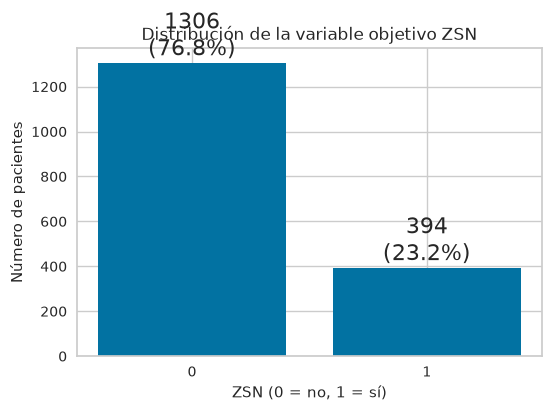

In [5]:
counts = df[TARGET].value_counts().sort_index()
percentages = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    counts.index.astype(str),
    counts.values
)

ax.set_title("Distribución de la variable objetivo ZSN")
ax.set_xlabel("ZSN (0 = no, 1 = sí)")
ax.set_ylabel("Número de pacientes")

for bar, count, percentage in zip(
    bars, counts.values, percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the fo

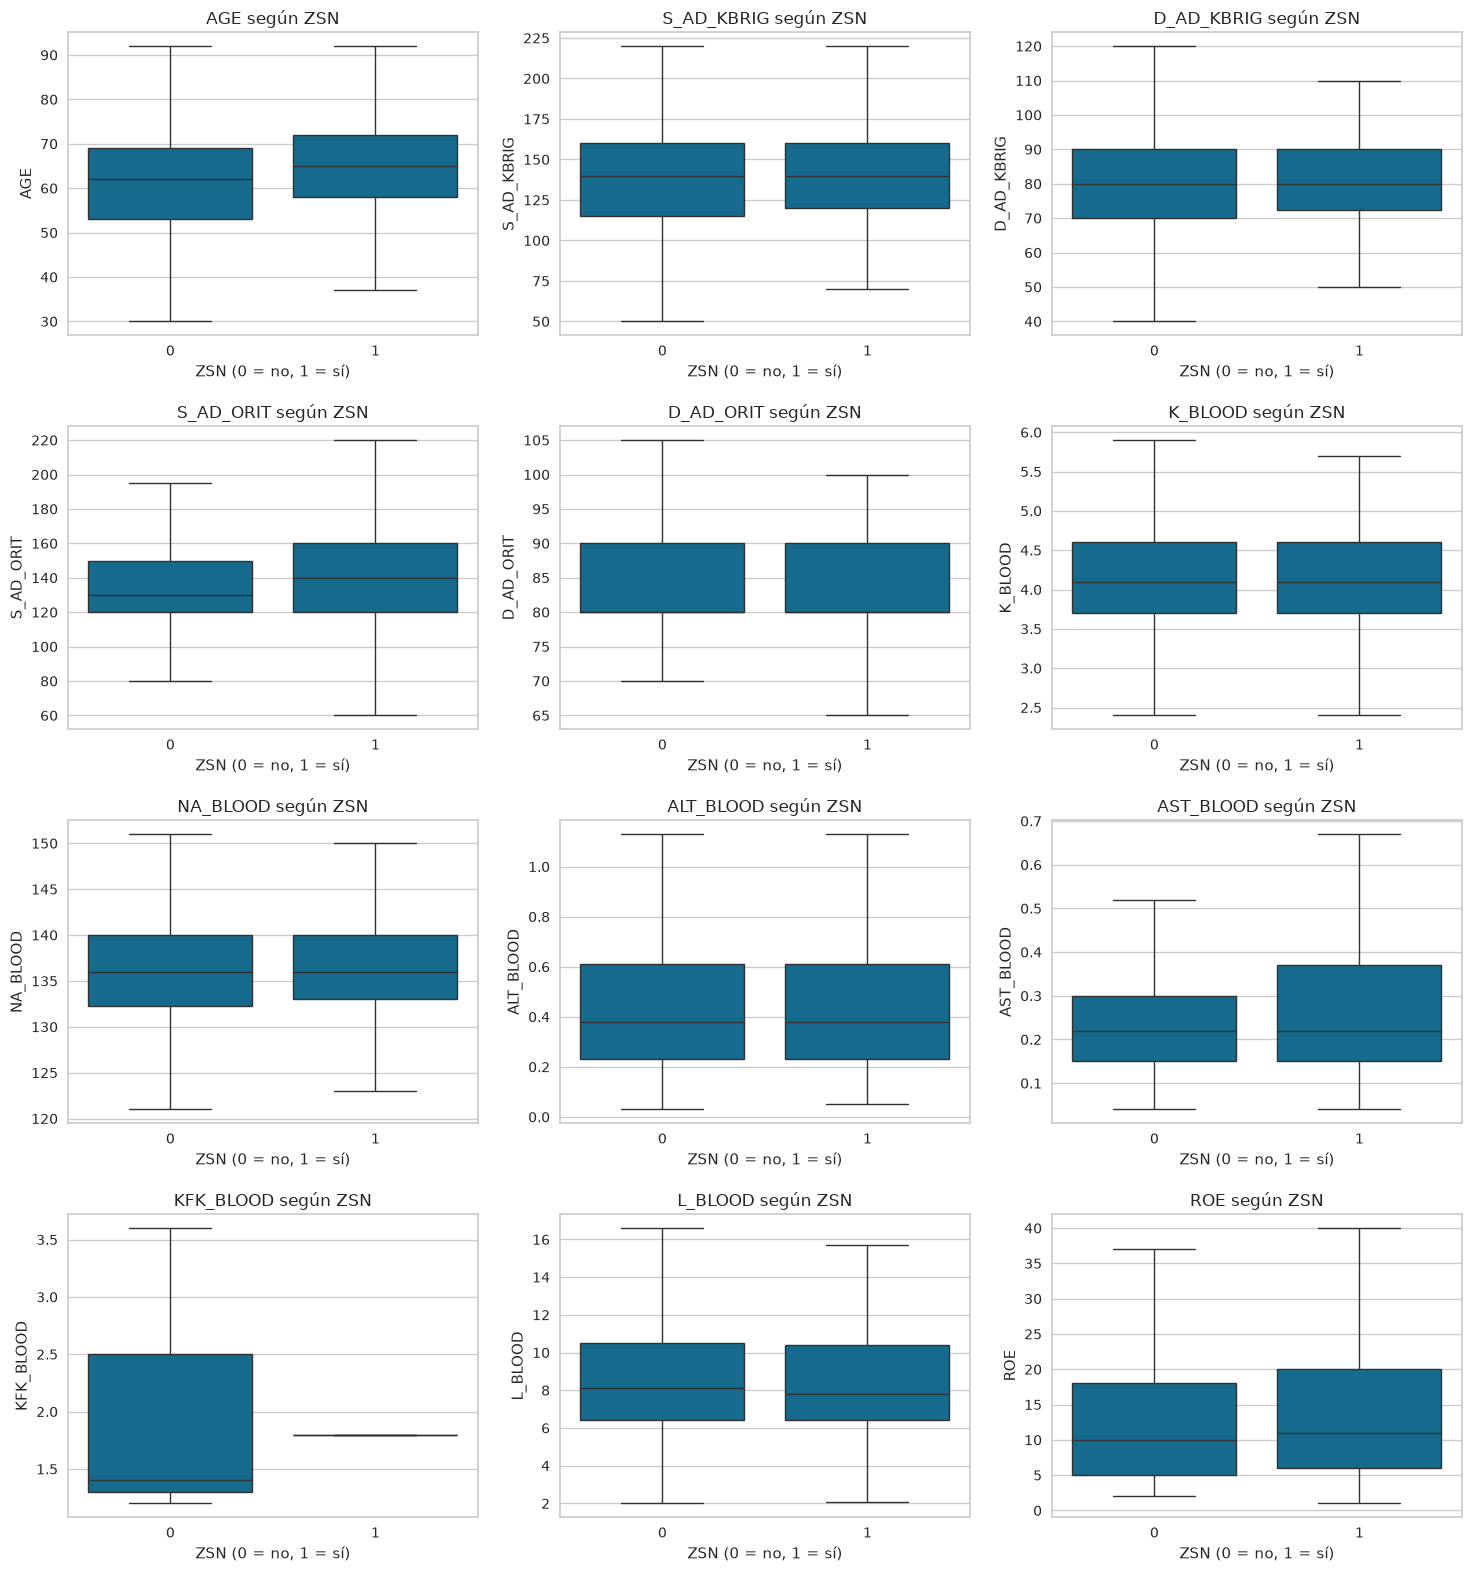

In [6]:
# Variables cuantitativas de interés clínico
numeric_candidates = [
    "AGE",
    "S_AD_KBRIG",
    "D_AD_KBRIG",
    "S_AD_ORIT",
    "D_AD_ORIT",
    "K_BLOOD",
    "NA_BLOOD",
    "ALT_BLOOD",
    "AST_BLOOD",
    "KFK_BLOOD",
    "L_BLOOD",
    "ROE"
]

# Convertirlas a formato numérico
for col in numeric_candidates:
    df[col] = pd.to_numeric(df[col], errors="coerce")

ncols = 3
nrows = int(np.ceil(len(numeric_candidates) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 4 * nrows)
)

axes = np.asarray(axes).flatten()

for ax, col in zip(axes, numeric_candidates):
    sns.boxplot(
        data=df,
        x=TARGET,
        y=col,
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"{col} según ZSN")
    ax.set_xlabel("ZSN (0 = no, 1 = sí)")
    ax.set_ylabel(col)

# Ocultar los ejes sobrantes
for ax in axes[len(numeric_candidates):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the fo

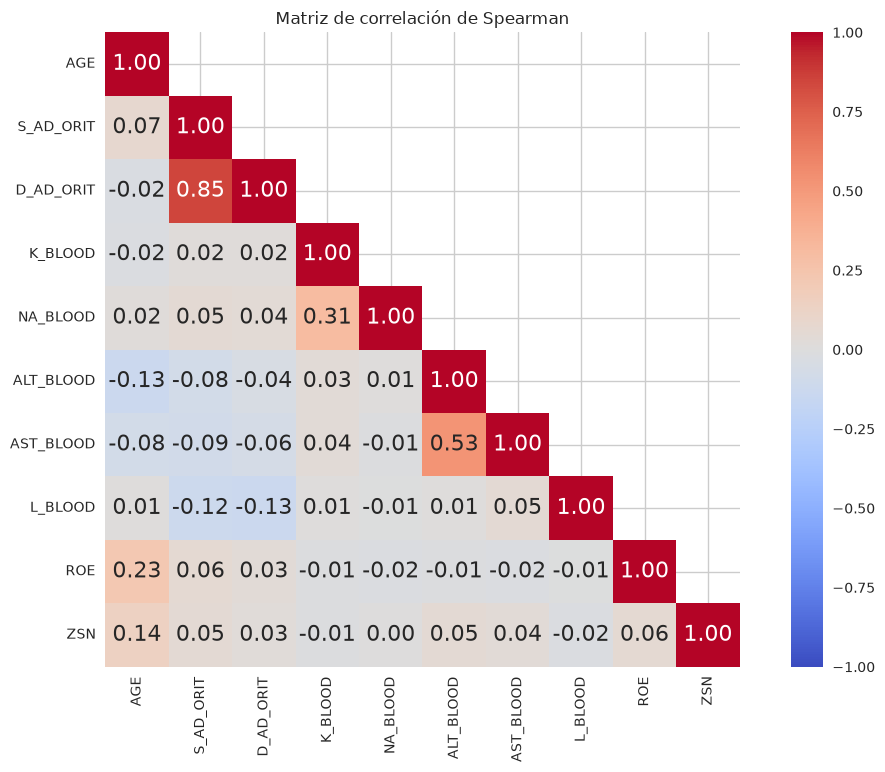

In [7]:
# Variables cuantitativas candidatas
corr_candidates = [
    "AGE",
    "S_AD_KBRIG",
    "D_AD_KBRIG",
    "S_AD_ORIT",
    "D_AD_ORIT",
    "K_BLOOD",
    "NA_BLOOD",
    "ALT_BLOOD",
    "AST_BLOOD",
    "KFK_BLOOD",
    "L_BLOOD",
    "ROE"
]

# Conservar las existentes con suficientes datos observados
corr_cols = [
    col for col in corr_candidates
    if col in df.columns
    and df[col].notna().mean() >= 0.40
]

# Añadir el objetivo para explorar asociaciones con ZSN
corr_df = df[corr_cols + [TARGET]].copy()
corr_df = corr_df.apply(pd.to_numeric, errors="coerce").astype(float)

corr_matrix = corr_df.corr(method="spearman")

# Mostrar únicamente la mitad inferior para facilitar la lectura
mask = np.triu(
    np.ones_like(corr_matrix, dtype=bool),
    k=1
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Matriz de correlación de Spearman")
plt.tight_layout()
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y[TARGET], test_size=0.30, random_state=42, stratify=y[TARGET]
)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1190, 111), (510, 111), (1190,), (510,))

In [43]:
medianImp = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(medianImp.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
print(np.isnan(X_train_imp).any())

X_test_imp = pd.DataFrame(medianImp.transform(X_test), columns=X_test.columns, index=X_test.index)
print(np.isnan(X_test_imp).any())

AGE           False
SEX           False
INF_ANAM      False
STENOK_AN     False
FK_STENOK     False
              ...  
ANT_CA_S_n    False
GEPAR_S_n     False
ASP_S_n       False
TIKL_S_n      False
TRENT_S_n     False
Length: 111, dtype: bool
AGE           False
SEX           False
INF_ANAM      False
STENOK_AN     False
FK_STENOK     False
              ...  
ANT_CA_S_n    False
GEPAR_S_n     False
ASP_S_n       False
TIKL_S_n      False
TRENT_S_n     False
Length: 111, dtype: bool


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [45]:
gnb = GaussianNB()
gnb.best_score_ = np.mean(cross_val_score(gnb,X_train_imp,y_train,cv=10))
print(gnb.best_score_)

0.31176470588235294


In [46]:
gnb_model = GaussianNB().fit(X_train_imp, y_train)
gnb_model.best_score_ = gnb.best_score_

print('Priors:', gnb_model.class_prior_)
print('Means:\n')
means =pd.DataFrame(gnb_model.theta_)
means.columns=X_train_imp.columns
means

Priors: [0.76806723 0.23193277]
Means:



,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,IBS_NASL,GB,SIM_GIPERT,DLIT_AG,...,NOT_NA_1_n,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n
0,61.111,0.649,0.513,2.174,1.217,1.133,0.019,1.345,0.036,3.207,...,0.313,0.098,0.067,0.267,0.132,0.659,0.734,0.752,0.014,0.181
1,64.797,0.547,0.576,2.341,1.254,1.170,0.000,1.500,0.036,3.558,...,0.399,0.138,0.116,0.301,0.105,0.721,0.652,0.754,0.007,0.243


In [47]:
from sklearn.metrics import classification_report
print(classification_report(y_test, gnb_model.predict(X_test_imp), target_names=['M', 'B']))
results_df = save_results(gnb_model, X_test_imp, y_test, 'GNB', results_df)

              precision    recall  f1-score   support

           M       0.85      0.15      0.25       392
           B       0.24      0.92      0.39       118

    accuracy                           0.33       510
   macro avg       0.55      0.53      0.32       510
weighted avg       0.71      0.33      0.28       510



findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the fo

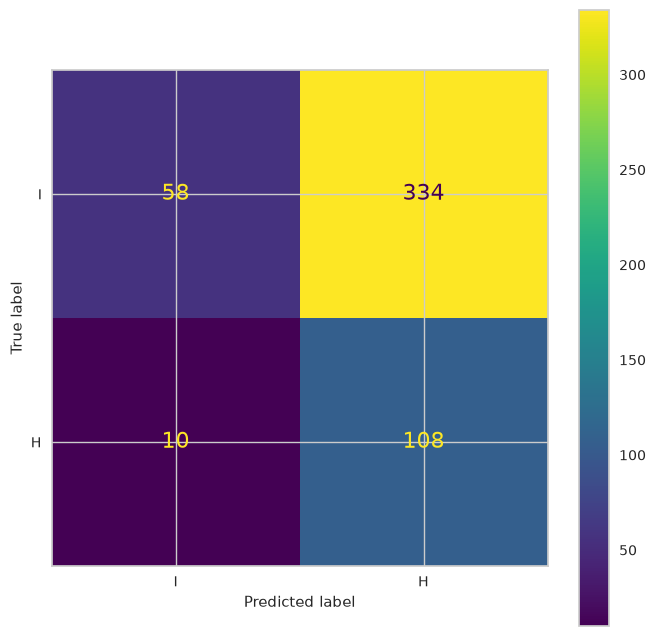

In [48]:
plt.figure(figsize=(8,8))
ConfusionMatrixDisplay.from_estimator(gnb_model, X_test_imp,y_test, display_labels=['I', 'H'], ax=plt.subplot())

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial, Liberation Sans, Bitstream Vera Sans, sans-serif
findfont: Generic family 'sans-serif' not found because none of the fo

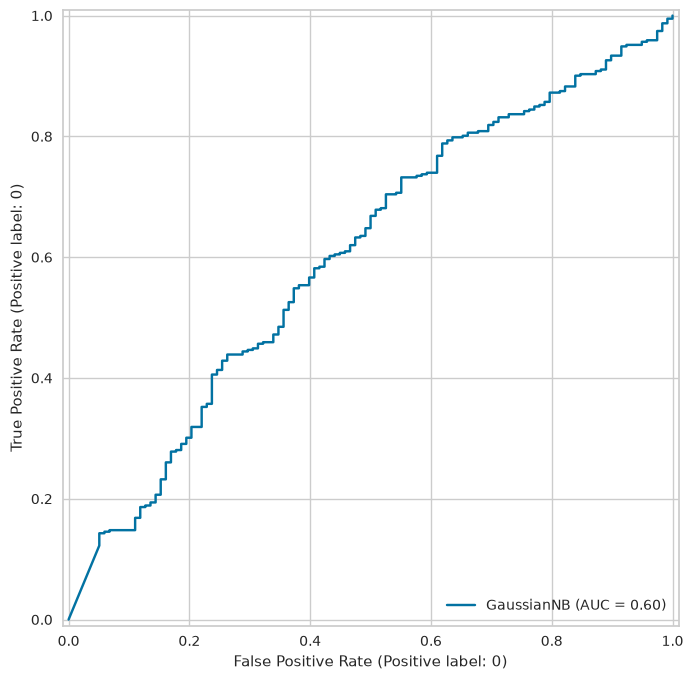

In [49]:
plt.figure(figsize=(8,8))
RocCurveDisplay.from_estimator(gnb_model, X_test_imp,y_test, pos_label=0, ax=plt.subplot())